# 00 — The simulator

> **Notation.** θ = (η, r, v₀) is the vector of the model's parameters: η the amplitude of the angular
> noise, r the interaction radius (the unit of length), v₀ the speed (distance per step). The heading of
> particle i is the angle αᵢ.

## Where we are and why this step exists

This is the first notebook of the series. We learn inference on the **Vicsek model**, a system where we
know the true answer because we simulate it ourselves. Before inferring anything, we need a simulator we
trust. This notebook builds that confidence and looks at the model's basic behaviour.

**What this notebook does:**

| § | question | tool |
|---|---|---|
| 1 | What exactly is simulated? | the equations of the model |
| 2 | What does it look like? | a video at three noise levels, and φ(t) |
| 3 | Is the code right? | two limits where the answer is known exactly |
| 4 | How long until the flock "forgets" its random start? | relaxation curves, dense vs sparse |
| 5 | How does order depend on noise? Does the update order matter? | a sweep of the stationary φ over η |
| 6 | What this taught us | |

**Scope:** few particles (N = 40). The region where order sets in is used only as a place where the
observables change fast.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from flockladder.animate import animate, show
from flockladder.observables import polarization
from flockladder.vicsek import VicsekParams, box_for_density, simulate

## 1. The model

### The idea in one paragraph

Each particle moves at constant speed and, at every step, turns to face the **average direction of its
neighbours** (everyone within distance $r$, itself included), plus a random error. Low noise makes
neighbours agree and groups travel together; high noise keeps everyone going in random directions. The
whole model is this competition between copying the neighbours and random error.

### The equations (`flockladder.vicsek`)

$N$ particles in a square box of side $L$ with periodic boundaries (leaving on one side means entering on
the opposite side). Particle $i$ has position $x_i$ and heading $\alpha_i$. Each step:

$$\alpha_i(t+1) = \arg \sum_{|x_j - x_i| \le r} e^{i\alpha_j(t)} + \xi_i, \qquad \xi_i \sim U[-\eta/2,\ \eta/2]$$

$$x_i(t+1) = x_i(t) + v_0\,(\cos\alpha_i(t+1),\ \sin\alpha_i(t+1)) \pmod L$$

- $\arg\sum e^{i\alpha_j}$ is the direction of the sum of the neighbours' unit vectors, i.e. their average direction.
- $\xi_i$ is uniform noise of total width $\eta$. $\eta = 0$ is no noise; $\eta = 2\pi$ means the new heading is
  completely random.
- Distances use the **minimum image**: in a periodic box, the distance to the closest copy.

**Two update orders.** The equations above are `angle_first`: align using the current positions, then
move with the *new* heading. The alternative, `move_first`, moves with the *old* heading and then aligns
using the new positions. The literature uses both. §5 checks whether the choice matters here.

**Units.** $r = 1$ defines the unit of length and one step the unit of time. The parameters that matter
are then η, $v_0$ (distance per step, in units of r) and the box size $L$ (equivalently the density
$\rho = N/L^2$, or the mean number of neighbours $\rho\pi r^2$).

### The order parameter

$$\varphi = \Big|\frac1N\sum_i e^{i\alpha_i}\Big|$$

- φ is the length of the average heading vector: **1** when all particles point the same way.
- It is about $\sqrt{\pi/4N} \approx 0.14$ for N = 40 when headings are random. It is not 0, because the
  average of 40 random unit vectors does not cancel exactly.

## 2. Seeing it

Three simulations with the **same seed** (so the same initial positions and headings) and three noise
levels: η = 0.5 (low), 2.5 (intermediate) and 5.0 (high).

**Settings:**
- N = 40 in a box of side L = 10 (ρ = 0.4). This box is sparse: each particle has on average about 1.3
  others within r = 1, so groups must form and meet.
- v₀ = 0.03, 1500 steps, drawn every 3 steps.

**How to read the video:**
- Each arrow is a particle and points along its heading. Its length is fixed (0.6 in units of r), not the speed.
- **Colour = heading**, so particles moving together share a colour.
- The black bar is the unit of length (r = 1).
- The line under each panel lists all parameters; the counter shows the step and the current φ.

The plot below the video shows φ(t) for the same three runs.

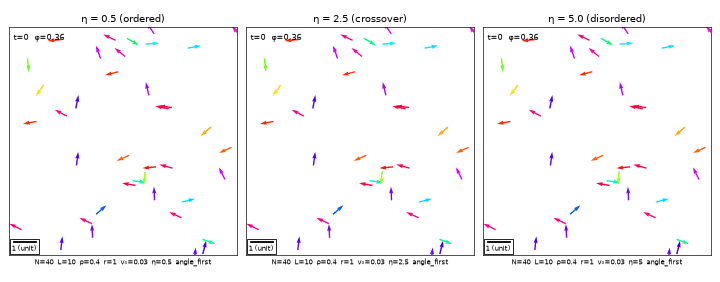

In [2]:
N = 40
L_sparse = box_for_density(N, 0.4)
trs = [
    simulate(VicsekParams(eta=eta, n=N, L=L_sparse), 1500, seed=0, record_every=3)
    for eta in (0.5, 2.5, 5.0)
]
gif = animate(
    trs,
    "three_noise_levels",
    gif=Path("../figures/three_noise_levels.gif"),
    stride=3,
    fps=15,
    dpi=60,
    titles=["η = 0.5 (ordered)", "η = 2.5 (crossover)", "η = 5.0 (disordered)"],
)
show(gif)

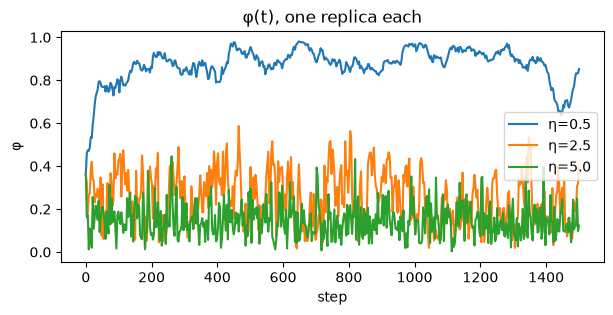

In [3]:
fig, ax = plt.subplots(figsize=(7, 3))
for tr, eta in zip(trs, (0.5, 2.5, 5.0)):
    ax.plot(tr.steps, polarization(tr.heading[:, 0]), label=f"η={eta}")
ax.set(xlabel="step", ylabel="φ", title="φ(t), one replica each")
ax.legend();

**How to read this.**
- **η = 0.5 (blue):** φ rises from the random value to ~0.8 within ~100 steps and then stays at 0.85–0.97.
  In the video, most particles join one large group of a single colour. Near step 1400 φ dips to ~0.65 and
  recovers. That is what a *finite* flock does: with 40 particles, a few leaving or joining the group
  visibly moves φ.
- **η = 2.5 (orange):** φ fluctuates between ~0.1 and ~0.55. Small groups form and dissolve; the colours
  stay mixed.
- **η = 5.0 (green):** φ stays near the random value (~0.1–0.3). There is no persistent alignment.
- **The fluctuations are large at every η.** One run of a few hundred steps gives a noisy φ. This is why
  later steps average over time and over replicas, and why the size of those fluctuations matters for
  inference (notebook 01).

## 3. Two known limits — is the code right?

Before trusting the simulator anywhere, check it where the answer is known exactly. The same checks run
automatically as tests in `tests/test_vicsek.py`; here they are as numbers.

- **Full noise (η = 2π).** The new heading is uniform on the circle whatever the neighbours do, so
  headings are independent. The mean length of the average of N random unit vectors is
  $\langle\varphi\rangle = \sqrt{\pi/(4N)}$, which is 0.1401 for N = 40. We use 4000 replicas so the
  comparison is precise.
- **No noise in a dense box (η = 0, ρ = 4).** Everybody sees many neighbours and copies them exactly, so
  the whole flock must end perfectly aligned: φ → 1. We check the *worst* of 5 replicas after 400 steps.

In [4]:
full = simulate(VicsekParams(eta=2 * np.pi, n=N), 5, n_replicas=4000, seed=6)
print(
    f"full noise: <phi> = {polarization(full.heading[-1]).mean():.4f}, expected {np.sqrt(np.pi / (4 * N)):.4f}"
)

quiet = simulate(VicsekParams(eta=0.0, n=N, L=box_for_density(N, 4.0)), 400, n_replicas=5, seed=5)
print(f"no noise:   min phi over replicas = {polarization(quiet.heading[-1]).min():.4f}")

full noise: <phi> = 0.1385, expected 0.1401
no noise:   min phi over replicas = 1.0000


**How to read this.**
- **Full noise:** measured 0.1385 against the exact 0.1401. The difference (1.1%) is within the expected
  scatter: the sd of φ over one replica is about 0.07, so the standard error over 4000 replicas is ≈ 0.001,
  and 0.0016 is under 2 standard errors. The test requires agreement within 5%.
- **No noise:** the worst replica reaches φ = 1.0000. The alignment rule and the periodic boundaries work.
- These limits test the two ingredients separately: the noise alone (first) and the alignment alone
  (second).

## 4. Relaxation — how long until the random start is forgotten?

Every simulation starts from random positions and headings. Averages taken before the system has
"forgotten" that start are biased, so we must discard an initial stretch, the **burn-in**. How long it
needs to be is measured here, not guessed.

**The comparison:**
- **Dense box (ρ = 4, dashed):** the first version of this notebook used it. Each particle sees ~12 of the
  40, so the flock is almost fully connected.
- **Sparse box (ρ = 0.4, solid):** the design used from now on, ten times sparser. Groups have to
  *find each other*, which should take longer.

Each curve is φ averaged over 40 replicas from random starts, at two noise levels (η = 0.5, 1.5).

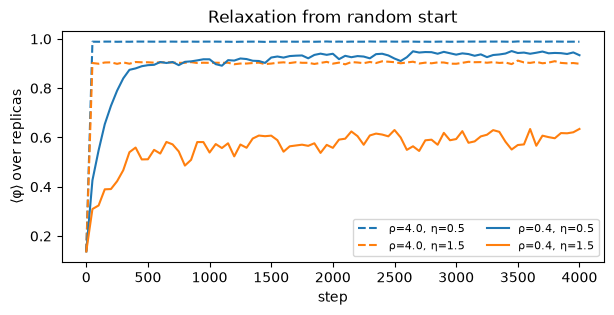

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
for rho, ls in ((4.0, "--"), (0.4, "-")):
    for eta, c in ((0.5, "C0"), (1.5, "C1")):
        tr = simulate(
            VicsekParams(eta=eta, n=N, L=box_for_density(N, rho)),
            4000,
            n_replicas=40,
            seed=2,
            record_every=50,
        )
        ax.plot(
            tr.steps, polarization(tr.heading).mean(axis=1), ls=ls, c=c, label=f"ρ={rho}, η={eta}"
        )
ax.set(xlabel="step", ylabel="⟨φ⟩ over replicas", title="Relaxation from random start")
ax.legend(fontsize=8, ncol=2);

**How to read this.**
- **Dense (dashed):** φ jumps to its final value in under ~100 steps and stays flat. Everyone already
  sees everyone.
- **Sparse, η = 0.5 (solid blue):** φ rises over ~500 steps to ~0.9 and then keeps creeping up slowly, to
  ~0.94 by step 4000. Small aligned groups form fast, then slowly merge.
- **Sparse, η = 1.5 (solid orange):** it reaches ~0.55 by ~500 steps, then drifts up to ~0.6 over the next
  few thousand, with visible fluctuations.
- **The stationary values differ a lot:** at η = 1.5, φ ≈ 0.90 dense against ≈ 0.6 sparse. Density
  (equivalently L/r) is a strong control parameter.

**Decision:**
- Burn-in 5000 steps, about 2.5× the slowest visible relaxation (~2000 steps).
- Then 5000 measured steps, because the sparse box also fluctuates more, so it needs longer averages.

## 5. Stationary φ(η), and does the update order matter?

**The question.** How does the long-run alignment depend on the noise? And do the two update orders of
§1 give different answers?

**Method:**
- For 14 values of η from 0 to 2π, run 20 replicas for 5000 burn-in + 5000 measured steps.
- Average φ over the measured steps in each replica, then over replicas. Error bars are the sd across
  replicas, i.e. the spread from one run to the next.
- Do this for `angle_first` and for `move_first`.
- The dotted line is the random-heading value √(π/4N).

It takes about a minute.

angle_first: 34s, 12 µs per replica-step


move_first: 35s, 12 µs per replica-step
max |difference| between update orders: 0.0213 at η = 1.93
across-replica sd of time-averaged φ: 0.0 – 0.038


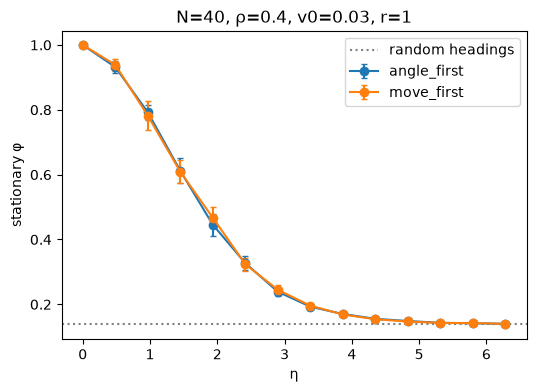

In [6]:
import time

RHO = 0.4
L_sweep = box_for_density(N, RHO)
etas = np.linspace(0, 2 * np.pi, 14)
BURN_IN, MEASURE, B = 5000, 5000, 20
sweep = {}
for update in ("angle_first", "move_first"):
    t0 = time.perf_counter()
    rows = []
    for k, eta in enumerate(etas):
        tr = simulate(
            VicsekParams(eta=eta, n=N, L=L_sweep, update=update),
            BURN_IN + MEASURE,
            n_replicas=B,
            seed=k,
            record_every=10,
        )
        per_replica = polarization(tr.heading[tr.steps > BURN_IN]).mean(axis=0)
        rows.append((per_replica.mean(), per_replica.std()))
    sweep[update] = np.array(rows)
    dt = time.perf_counter() - t0
    print(
        f"{update}: {dt:.0f}s, {1e6 * dt / (len(etas) * (BURN_IN + MEASURE) * B):.0f} µs per replica-step"
    )

fig, ax = plt.subplots(figsize=(6, 4))
for update, r in sweep.items():
    ax.errorbar(etas, r[:, 0], yerr=r[:, 1], marker="o", capsize=2, label=update)
ax.axhline(np.sqrt(np.pi / (4 * N)), ls=":", c="gray", label="random headings")
ax.set(xlabel="η", ylabel="stationary φ", title=f"N={N}, ρ={RHO}, v0=0.03, r=1")
ax.legend()
diff = np.abs(sweep["angle_first"][:, 0] - sweep["move_first"][:, 0])
print(
    "max |difference| between update orders:",
    diff.max().round(4),
    "at η =",
    etas[diff.argmax()].round(2),
)
print(
    "across-replica sd of time-averaged φ:",
    sweep["angle_first"][:, 1].min().round(3),
    "–",
    sweep["angle_first"][:, 1].max().round(3),
)

**How to read this.**
- **A smooth crossover, not a jump.** φ goes from 1 at η = 0 to the random value (0.14) at η ≳ 5. The steepest
  part is around η ≈ 1–2.5. With only 40 particles the change is smooth.
- **The two update orders nearly coincide.** The largest difference is 0.021, at η ≈ 1.9, where the error
  bars are largest. With 20 replicas the standard error of each mean is about sd/√20 ≈ 0.008, so 0.021 is
  about 2 standard errors of the difference: suggestive, not resolved. In the dense box the difference was
  ≤ 0.005. We keep `angle_first`.
- **Run-to-run spread:** the sd across replicas of the time-averaged φ is 0 at η = 0 (every run aligns
  perfectly) and up to 0.038 in the crossover. Even after averaging over 5000 steps, two runs at the same
  parameters differ by several percent in φ. How much each observable fluctuates is the first question of [notebook 01](01_observables.ipynb).
- **Cost:** ~11 µs per replica-step (one step of all 40 particles in one replica), so the whole sweep takes
  about a minute.

## 6. What this taught us

- **The simulator passes both exact limits:** full noise gives √(π/4N) within 1.1%, and no noise gives perfect
  alignment.
- **A smooth crossover** from order to disorder, with no sharp transition at N = 40.
- **Density is a strong control parameter.** At η = 1.5, stationary φ is ≈ 0.90 in the dense box (ρ = 4) and
  ≈ 0.6 in the sparse one (ρ = 0.4).
  - The dense box is nearly fully connected: each particle sees ~12 of 40.
  - In the sparse box a particle sees ~1.3 others on average, so groups form, split and merge (see §2).
  - With r = 1 as the unit of length, the geometric parameter is L/r (equivalently ρr²). The "η–r
    degeneracy" of [notebook 04](04_identifiability.ipynb) is really η vs L/r.
- **Relaxation is much slower when sparse:** < 100–250 steps at ρ = 4 against ~2000 at ρ = 0.4. Burn-in and
  measurement lengths (5000 + 5000) were chosen from §4, not guessed.
- **The update orders are close but not identical** in the sparse box (up to 0.021, about 2 standard errors).
- **Run-to-run fluctuations are several percent** in the crossover, even after long time averages.
- *Looking ahead:* the dense box is not "trivial because r barely matters". Notebooks 01 and 04 show that r
  *does* matter there, and that the dense box is even more precise per run. What is trivial there is the
  geometry: always one cluster.